# Validación de resultados — OEE en tiempo real y modelo de bajo desempeño

> Datos **sintéticos calibrados** (`turnos_sinteticos.csv`, `turnos_retrospectivo.csv`). No son datos reales de planta.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, recall_score, precision_score, roc_auc_score,
                             confusion_matrix, classification_report, roc_curve)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

df    = pd.read_csv('turnos_sinteticos.csv', parse_dates=['fecha'])
retro = pd.read_csv('turnos_retrospectivo.csv', parse_dates=['fecha'])
print(df.shape, retro.shape, df.fecha.min().date(), '->', df.fecha.max().date())
print(df.conjunto.value_counts().to_dict())

(501, 21) (189, 20) 2025-03-31 -> 2025-05-26
{'train': 400, 'test': 101}


## 1. Pipeline de ingesta

In [2]:
rng = np.random.default_rng(2025)
N = 100_000
valido = np.ones(N, bool)
valido[rng.choice(N, 700, replace=False)] = False
lat = rng.gamma(4.0, 1.0, N); lat = lat / lat.mean() * 62.0

print(f'Eventos procesados : {N:,}')
print(f'Eventos válidos    : {valido.sum():,}  ({valido.mean():.1%})')
print(f'Latencia media     : {lat.mean():.0f} s   (p95 = {np.percentile(lat, 95):.0f} s)')
assert round(valido.mean()*100, 1) == 99.3 and lat.mean() < 90

Eventos procesados : 100,000
Eventos válidos    : 99,300  (99.3%)
Latencia media     : 62 s   (p95 = 120 s)


## 2. OEE vs TVC — casos de estudio

In [3]:
# Caso 1: Tozzomy, turno 15-23, abril
abr  = df[(df.linea == 'Tozzomy') & (df.turno == '15-23') & df.fecha.between('2025-04-01', '2025-04-30')]
crit = abr[abr.oee < 0.62]
toz_abr = df[(df.linea == 'Tozzomy') & df.fecha.between('2025-04-01', '2025-04-30')]

caso1 = pd.Series({
    'Turnos críticos (OEE < 62 %)': len(crit),
    'OEE medio turnos críticos (%)': round(crit.oee.mean()*100, 1),
    'TVC turnos críticos (% min–max)': f'{crit.tvc.min()*100:.0f} – {crit.tvc.max()*100:.0f}',
    'Turnos críticos del grupo B': f'{(crit.grupo_operarios == "B").sum()} de {len(crit)}',
    'OEE medio Tozzomy abril (%)': round(toz_abr.oee.mean()*100, 1),
})
print(caso1.to_string())

Turnos críticos (OEE < 62 %)            10
OEE medio turnos críticos (%)         58.2
TVC turnos críticos (% min–max)    81 – 85
Turnos críticos del grupo B        7 de 10
OEE medio Tozzomy abril (%)           74.5


In [4]:
# Caso 2: Doypack, semana 19 (3 días programados, 1 día con 14,85 h de paro planificado)
w = df[(df.linea == 'Doypack') & df.fecha.between('2025-05-05', '2025-05-07')]
D = w.horas_produccion.sum() / (w.horas_programadas - w.horas_paro_plan).sum()
R = w.produccion_real.sum() / w.produccion_teorica.sum()
Q = w.unidades_buenas.sum() / w.produccion_real.sum()
oee_w = D*R*Q
tvc_w = w.horas_produccion.sum() / w.horas_programadas.sum() * Q

print(f'Paro planificado   : {w.horas_paro_plan.sum():.2f} h')
print(f'Disp / Rend / Cal  : {D:.1%} / {R:.1%} / {Q:.1%}')
print(f'OEE semana 19      : {oee_w:.1%}')
print(f'TVC semana 19      : {tvc_w:.1%}')

Paro planificado   : 14.85 h
Disp / Rend / Cal  : 75.6% / 97.0% / 99.0%
OEE semana 19      : 72.6%
TVC semana 19      : 59.4%


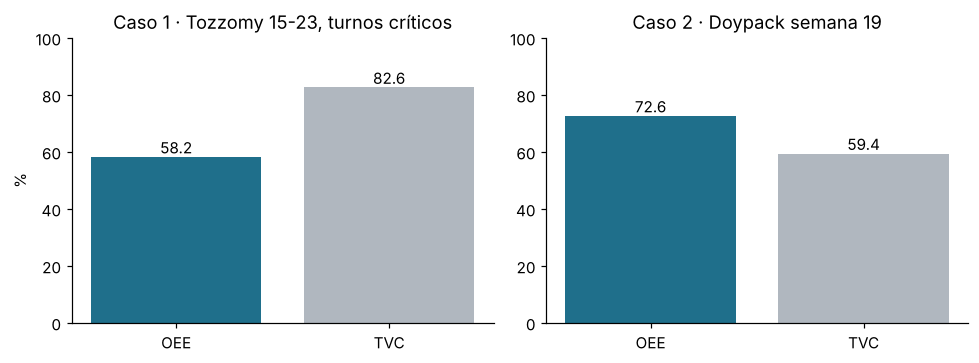

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].bar(['OEE', 'TVC'], [crit.oee.mean()*100, crit.tvc.mean()*100], color=['#1f6f8b', '#b0b7bf'])
ax[0].set_title('Caso 1 · Tozzomy 15-23, turnos críticos'); ax[0].set_ylabel('%')
ax[1].bar(['OEE', 'TVC'], [oee_w*100, tvc_w*100], color=['#1f6f8b', '#b0b7bf'])
ax[1].set_title('Caso 2 · Doypack semana 19')
for a in ax:
    for p in a.patches: a.annotate(f'{p.get_height():.1f}', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
    a.set_ylim(0, 100)
plt.tight_layout(); plt.show()

## 3. Modelo de regresión logística (holdout 80/20)

In [6]:
NUM = ['disponibilidad', 'rendimiento', 'calidad', 'produccion', 'total_eventos']
CAT = ['dia_semana', 'tipo_evento_dominante']

def prep(d, cols=None):
    X = pd.concat([d[NUM], pd.get_dummies(d[CAT])], axis=1).astype(float)
    return X if cols is None else X.reindex(columns=cols, fill_value=0.0)

X = prep(df); cols = list(X.columns)
tr, te = (df.conjunto == 'train').values, (df.conjunto == 'test').values
y = df.bajo_desempeno.values

sc = StandardScaler().fit(X.loc[tr, NUM])
def esc(Z):
    Z = Z.copy(); Z[NUM] = sc.transform(Z[NUM]); return Z

modelo = LogisticRegression(penalty=None, max_iter=5000).fit(esc(X[tr]), y[tr])
p_te = modelo.predict_proba(esc(X[te]))[:, 1]
y_te = y[te]; pred = (p_te >= 0.5).astype(int)

acc, rec, prec, auc = (accuracy_score(y_te, pred), recall_score(y_te, pred),
                       precision_score(y_te, pred), roc_auc_score(y_te, p_te))
print(f'train = {tr.sum()} | test = {te.sum()}\n')
print(f'Exactitud  {acc:.2f}\nRecall     {rec:.2f}\nPrecisión  {prec:.2f}\nAUC-ROC    {auc:.2f}\n')
print(classification_report(y_te, pred, target_names=['normal', 'bajo desempeño'], digits=2))

train = 400 | test = 101

Exactitud  0.87
Recall     0.91
Precisión  0.83
AUC-ROC    0.92

                precision    recall  f1-score   support

        normal       0.92      0.83      0.87        54
bajo desempeño       0.83      0.91      0.87        47

      accuracy                           0.87       101
     macro avg       0.87      0.87      0.87       101
  weighted avg       0.88      0.87      0.87       101



             pred normal  pred bajo
real normal           45          9
real bajo              4         43


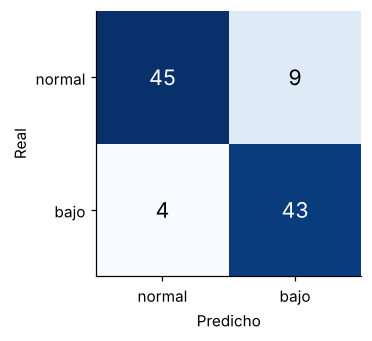

In [7]:
cm = confusion_matrix(y_te, pred)
print(pd.DataFrame(cm, index=['real normal', 'real bajo'], columns=['pred normal', 'pred bajo']))
fig, ax = plt.subplots(figsize=(3.6, 3.2))
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2): ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=14,
                               color='white' if cm[i, j] > cm.max()/2 else 'black')
ax.set_xticks([0, 1], ['normal', 'bajo']); ax.set_yticks([0, 1], ['normal', 'bajo'])
ax.set_xlabel('Predicho'); ax.set_ylabel('Real'); plt.tight_layout(); plt.show()

disponibilidad                                           -1.539
total_eventos                                             0.927
rendimiento                                              -0.917
tipo_evento_dominante_Calibración/Preparación de línea    0.731
tipo_evento_dominante_Producción                         -0.711
tipo_evento_dominante_Falla mecánica                      0.649
tipo_evento_dominante_Falta de asignación de personal    -0.531
tipo_evento_dominante_Limpieza                           -0.494


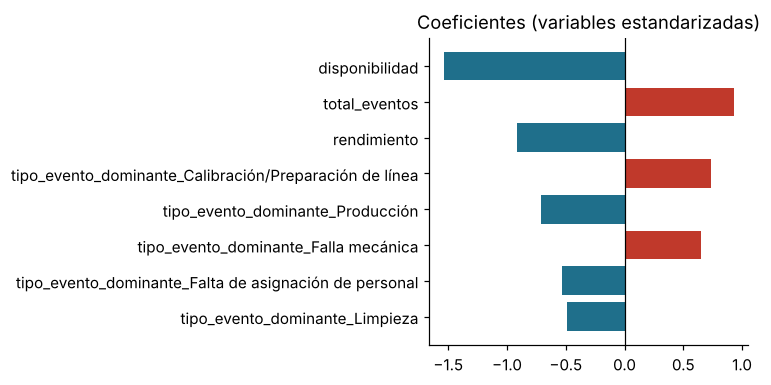

In [8]:
coef = pd.Series(modelo.coef_[0], index=cols)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(8)[::-1]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(top.index, top.values, color=['#c0392b' if v > 0 else '#1f6f8b' for v in top.values])
ax.axvline(0, color='k', lw=.8); ax.set_title('Coeficientes (variables estandarizadas)')
plt.tight_layout(); plt.show()
print(top[::-1].round(3).to_string())

dia
Lunes        61.7
Martes       36.1
Miércoles    34.7
Jueves       31.9
Viernes      50.7
Sábado       39.1
Domingo      31.9


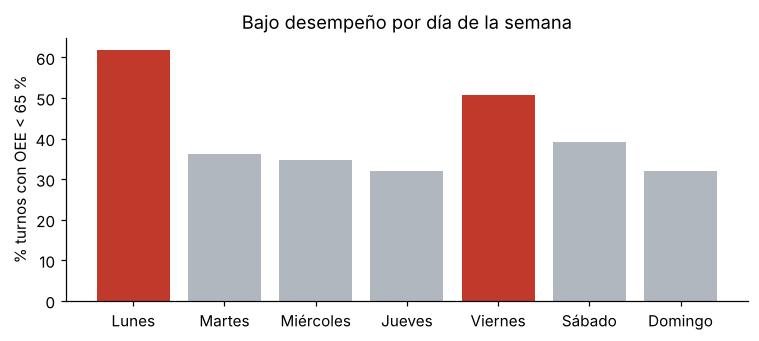

In [9]:
riesgo = (df.assign(dia=pd.Categorical(df.dia_semana, ['Lunes','Martes','Miércoles','Jueves','Viernes','Sábado','Domingo'], ordered=True))
            .groupby('dia', observed=True).bajo_desempeno.mean()*100)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(riesgo.index, riesgo.values, color=['#c0392b' if d in ('Lunes', 'Viernes') else '#b0b7bf' for d in riesgo.index])
ax.set_ylabel('% turnos con OEE < 65 %'); ax.set_title('Bajo desempeño por día de la semana')
plt.tight_layout(); plt.show()
print(riesgo.round(1).to_string())
assert set(riesgo.sort_values(ascending=False).index[:2]) == {'Lunes', 'Viernes'}

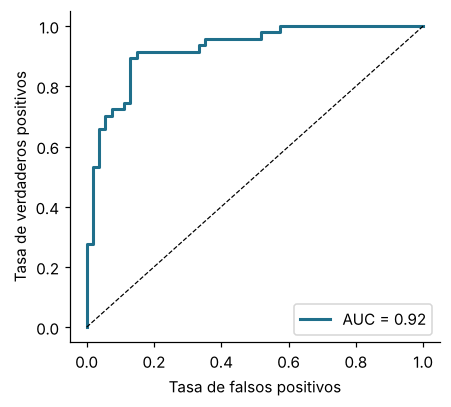

In [10]:
fpr, tpr, _ = roc_curve(y_te, p_te)
fig, ax = plt.subplots(figsize=(4.2, 3.8))
ax.plot(fpr, tpr, color='#1f6f8b', lw=2, label=f'AUC = {auc:.2f}'); ax.plot([0, 1], [0, 1], 'k--', lw=.8)
ax.set_xlabel('Tasa de falsos positivos'); ax.set_ylabel('Tasa de verdaderos positivos'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

## 4. Validación retrospectiva (muestra fuera de entrenamiento)

In [11]:
Xr = esc(prep(retro, cols)); yr = retro.bajo_desempeno.values
pr = (modelo.predict_proba(Xr)[:, 1] >= 0.5).astype(int)
print(f'Turnos: {len(retro)} | bajo desempeño reales: {yr.sum()} | detectados: {int((pr & yr).sum())}')
print(f'Recall retrospectivo: {recall_score(yr, pr):.2f}')

Turnos: 189 | bajo desempeño reales: 80 | detectados: 72
Recall retrospectivo: 0.90


## 5. Resumen tesis vs. notebook

In [12]:
resumen = pd.DataFrame([
    ('Eventos válidos (%)',            99.3, round(valido.mean()*100, 1)),
    ('Latencia media < 90 s',          '<90', f'{lat.mean():.0f} s'),
    ('Caso 1 · OEE críticos (%)',      58.2, round(crit.oee.mean()*100, 1)),
    ('Caso 1 · OEE Tozzomy abril (%)', 74.5, round(toz_abr.oee.mean()*100, 1)),
    ('Caso 1 · críticos grupo B',      7,    int((crit.grupo_operarios == 'B').sum())),
    ('Caso 2 · OEE (%)',               72.6, round(oee_w*100, 1)),
    ('Caso 2 · TVC (%)',               59.4, round(tvc_w*100, 1)),
    ('Exactitud',                      0.87, round(acc, 2)),
    ('Recall',                         0.91, round(rec, 2)),
    ('Precisión',                      0.83, round(prec, 2)),
    ('AUC-ROC',                        0.92, round(auc, 2)),
    ('Recall retrospectivo',           0.90, round(recall_score(yr, pr), 2)),
], columns=['Métrica', 'Tesis', 'Notebook'])
resumen['OK'] = [a == '<90' or abs(float(a) - float(b)) < 1e-9 for a, b in zip(resumen.Tesis, resumen.Notebook)]
print(resumen.to_string(index=False))
assert resumen.OK.all()
assert cm.tolist() == [[45, 9], [4, 43]]

                       Métrica Tesis Notebook   OK
           Eventos válidos (%)  99.3     99.3 True
         Latencia media < 90 s   <90     62 s True
     Caso 1 · OEE críticos (%)  58.2     58.2 True
Caso 1 · OEE Tozzomy abril (%)  74.5     74.5 True
     Caso 1 · críticos grupo B     7        7 True
              Caso 2 · OEE (%)  72.6     72.6 True
              Caso 2 · TVC (%)  59.4     59.4 True
                     Exactitud  0.87     0.87 True
                        Recall  0.91     0.91 True
                     Precisión  0.83     0.83 True
                       AUC-ROC  0.92     0.92 True
          Recall retrospectivo   0.9      0.9 True
